<a href="https://colab.research.google.com/github/AmitabhTS/AML-LAB-EXPERIMENTS/blob/main/AML2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original Dataset Shape: (2060, 24)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2060 entries, 0 to 2059
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2036 non-null   float64
 1   blue           2028 non-null   object 
 2   clock_speed    2022 non-null   float64
 3   dual_sim       2030 non-null   object 
 4   fc             2030 non-null   float64
 5   four_g         2033 non-null   object 
 6   int_memory     2034 non-null   float64
 7   m_dep          2033 non-null   float64
 8   mobile_wt      2026 non-null   float64
 9   n_cores        2035 non-null   float64
 10  pc             2032 non-null   float64
 11  px_height      2035 non-null   float64
 12  px_width       2028 non-null   float64
 13  ram            2032 non-null   float64
 14  sc_h           2030 non-null   float64
 15  sc_w           2032 non-null   float64
 16  talk_time      2021 non-null   float64


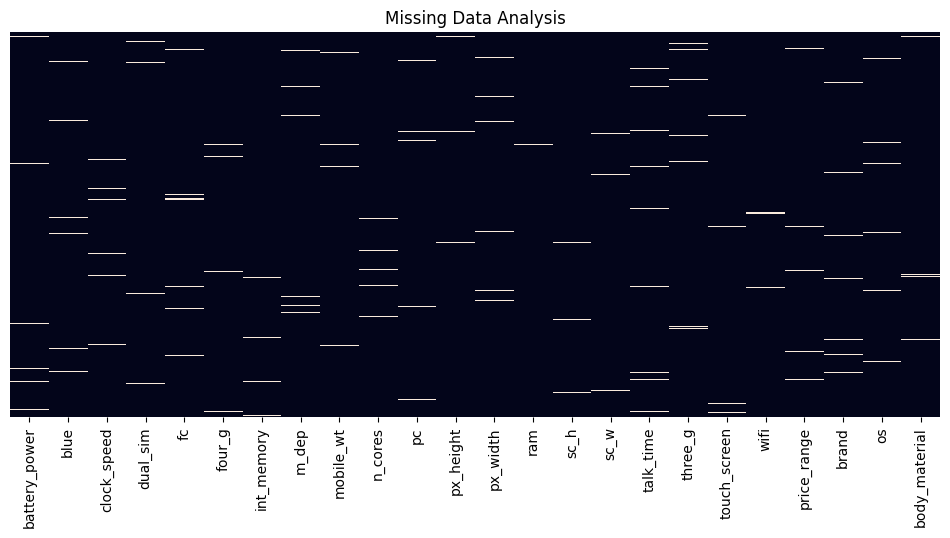


Missing values after preprocessing:
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
brand            0
os               0
body_material    0
dtype: int64

Converting Text Columns to Numerical Values...
Label Encoded (Binary): blue
Label Encoded (Binary): dual_sim
Label Encoded (Binary): four_g
Label Encoded (Binary): three_g
Label Encoded (Binary): touch_screen
Label Encoded (Binary): wifi
One-Hot Encoded: brand
One-Hot Encoded: os
One-Hot Encoded: body_material

Dataset Shape After Categorical Encoding: (2060, 33)

Continuous Columns Selected for Outlier Analysis (12): ['battery_power', 'clock_speed', 'fc', 'int_memory', 'mobile_wt', 'pc',

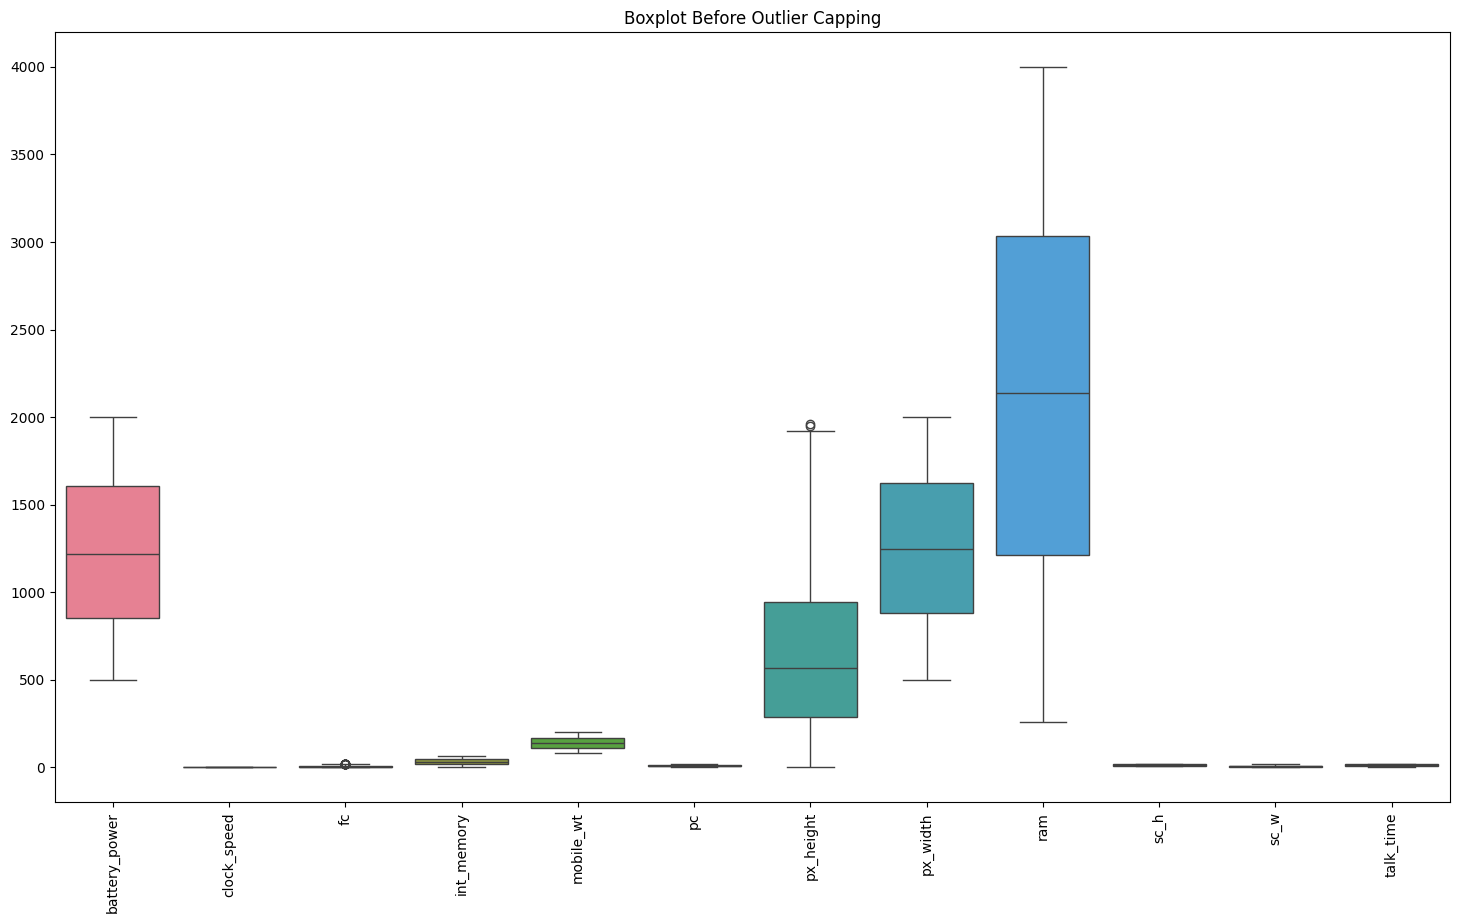


Original Dataset Shape: (2060, 33)
Refined Dataset Shape (Rows Preserved via Capping): (2060, 33)

Missing Values in Refined Dataset:
battery_power            0
blue                     0
clock_speed              0
dual_sim                 0
fc                       0
four_g                   0
int_memory               0
m_dep                    0
mobile_wt                0
n_cores                  0
pc                       0
px_height                0
px_width                 0
ram                      0
sc_h                     0
sc_w                     0
talk_time                0
three_g                  0
touch_screen             0
wifi                     0
price_range              0
brand_Motorola           0
brand_OnePlus            0
brand_Realme             0
brand_Samsung            0
brand_Vivo               0
brand_Xiaomi             0
os_Android 11            0
os_Android 12            0
os_Android 13            0
os_iOS                   0
body_material_Glass      0
b

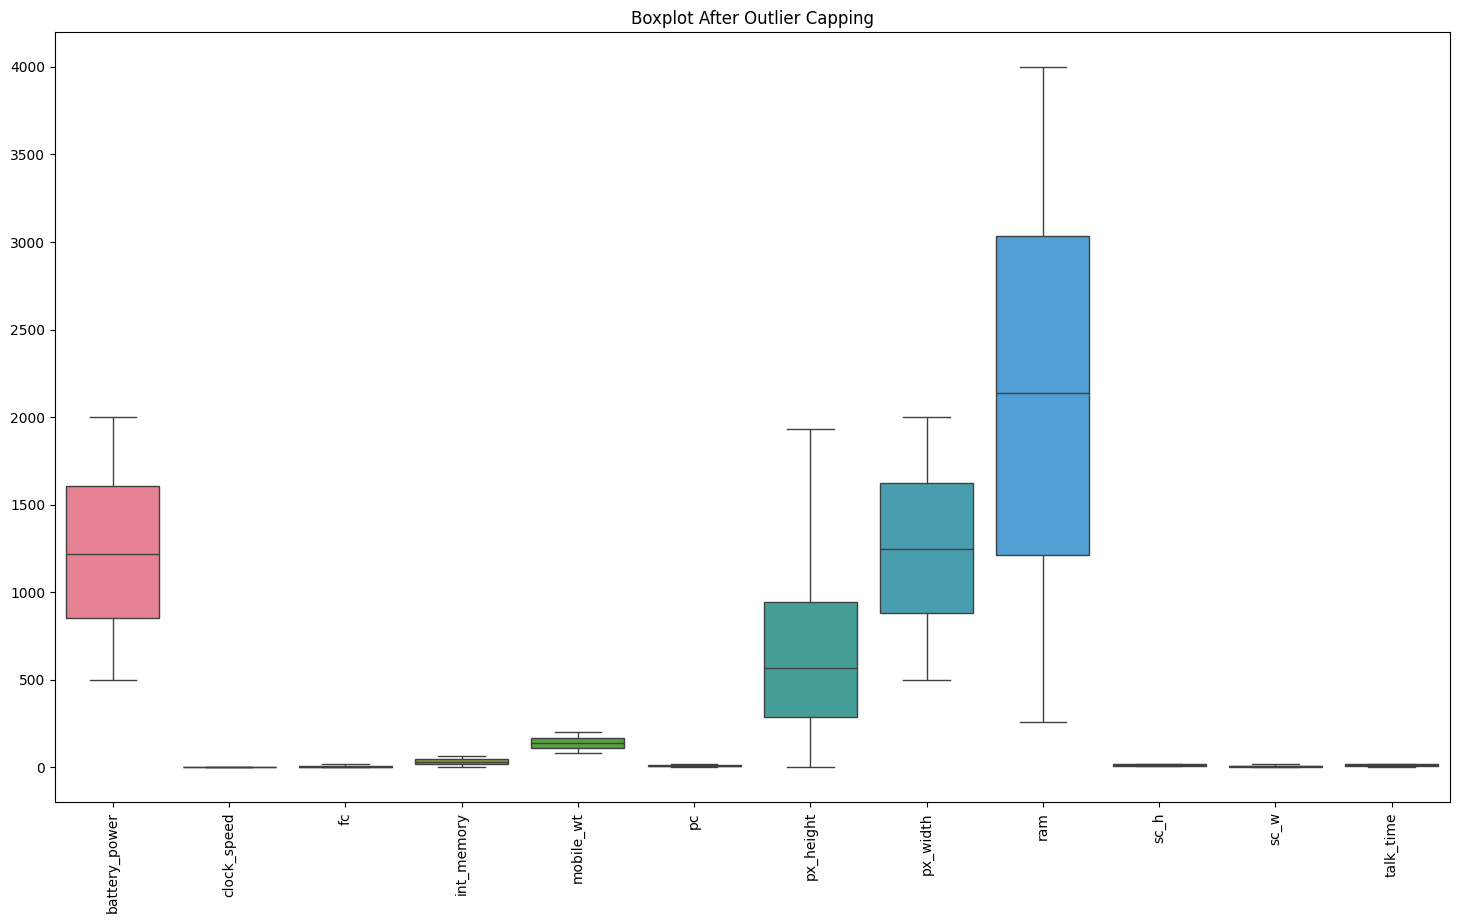


Duplicate Records: 60
Shape after removing duplicates: (2000, 33)

Refined dataset saved successfully as CSV and Excel (.xlsx)!

Final Refined Dataset:
   battery_power  blue  clock_speed  dual_sim   fc  four_g  int_memory  m_dep  \
0          871.0     0          0.6         0  2.0       0        52.0    0.1   
1         1658.0     1          1.4         0  0.0       1        39.0    0.7   
2          987.0     1          2.3         0  9.0       0        17.0    0.8   
3         1703.0     1          0.5         0  5.0       1        23.0    0.2   
4          851.0     0          0.5         0  3.0       0        21.0    0.4   

   mobile_wt  n_cores  ...  brand_Realme  brand_Samsung  brand_Vivo  \
0      178.0      3.0  ...             0              0           1   
1      182.0      1.0  ...             0              0           0   
2      124.0      7.0  ...             1              0           0   
3       92.0      6.0  ...             0              0           1   
4    

In [ ]:
# Experiment 2
# Data Preprocessing, Outlier/Missing Data Analysis, Capping & Export
# Mobile Price Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------

df = pd.read_csv("/content/drive/My Drive/Colab Notebooks/train_modified_balanced.csv")

print("Original Dataset Shape:", df.shape)

# --------------------------------------------------
# 2. Display basic information
# --------------------------------------------------

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
print(df.head())

# Identify text (categorical) columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns
print(f"\nCategorical (Text) Columns Found ({len(categorical_columns)}):", list(categorical_columns))

# --------------------------------------------------
# 3. Check missing values
# --------------------------------------------------

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

# Calculate missing-value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage)

# --------------------------------------------------
# 4. Visualize missing values
# --------------------------------------------------

plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Data Analysis")
plt.show()

# --------------------------------------------------
# 5. Handle missing values
# --------------------------------------------------

# Handle missing numerical values using Median
numeric_columns = df.select_dtypes(include=np.number).columns
for column in numeric_columns:
    if df[column].isnull().sum() > 0:
        median_value = df[column].median()
        df[column] = df[column].fillna(median_value)

# Handle missing categorical (text) values using Mode
for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        mode_value = df[column].mode()[0]
        df[column] = df[column].fillna(mode_value)

print("\nMissing values after preprocessing:")
print(df.isnull().sum())

# --------------------------------------------------
# 6. Convert Text (Categorical) into Numerical Values
# --------------------------------------------------

print("\nConverting Text Columns to Numerical Values...")

for col in categorical_columns:
    unique_count = df[col].nunique()

    if unique_count == 2:
        # Binary text -> Label Encoding (0 and 1)
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
        print(f"Label Encoded (Binary): {col}")

    elif unique_count > 2 and unique_count <= 10:
        # Multi-class nominal text -> One-Hot Encoding
        df = pd.get_dummies(df, columns=[col], drop_first=True, dtype=int)
        print(f"One-Hot Encoded: {col}")

    else:
        # High cardinality text -> Label Encoding
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        print(f"Label Encoded (High Cardinality): {col}")

print("\nDataset Shape After Categorical Encoding:", df.shape)

# Identify continuous features ONLY (ignore binary/encoded columns with <= 10 unique values)
numeric_columns = df.select_dtypes(include=np.number).columns
continuous_columns = [col for col in numeric_columns if df[col].nunique() > 10]

print(f"\nContinuous Columns Selected for Outlier Analysis ({len(continuous_columns)}):", continuous_columns)

# --------------------------------------------------
# 7. Detect outliers using IQR (Continuous Features Only)
# --------------------------------------------------

print("\nOutlier Analysis Before Capping:")

outlier_counts = {}

for column in continuous_columns:

    Q1 = np.percentile(df[column], 25)
    Q3 = np.percentile(df[column], 75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_counts[column] = len(outliers)
    print(column, "->", len(outliers), "outliers")

# --------------------------------------------------
# 8. Display outlier counts
# --------------------------------------------------

print("\nOutlier Count for Each Continuous Feature:")

for column, count in outlier_counts.items():
    print(column, ":", count)

# --------------------------------------------------
# 9. Visualize outliers using boxplots
# --------------------------------------------------

plt.figure(figsize=(18, 10))

sns.boxplot(
    data=df[continuous_columns]
)

plt.xticks(rotation=90)
plt.title("Boxplot Before Outlier Capping")
plt.show()

# --------------------------------------------------
# 10. Cap outliers using IQR (Winsorization)
# --------------------------------------------------

refined_df = df.copy()

for column in continuous_columns:

    Q1 = np.percentile(refined_df[column], 25)
    Q3 = np.percentile(refined_df[column], 75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Cap continuous values at lower and upper limits
    refined_df[column] = np.where(
        refined_df[column] < lower_limit,
        lower_limit,
        np.where(
            refined_df[column] > upper_limit,
            upper_limit,
            refined_df[column]
        )
    )

# --------------------------------------------------
# 11. Compare dataset sizes
# --------------------------------------------------

print("\nOriginal Dataset Shape:", df.shape)
print("Refined Dataset Shape (Rows Preserved via Capping):", refined_df.shape)

# --------------------------------------------------
# 12. Check missing values again
# --------------------------------------------------

print("\nMissing Values in Refined Dataset:")
print(refined_df.isnull().sum())

# --------------------------------------------------
# 13. Check outliers again (Continuous Features Only)
# --------------------------------------------------

print("\nOutlier Analysis After Capping:")

for column in continuous_columns:

    Q1 = np.percentile(refined_df[column], 25)
    Q3 = np.percentile(refined_df[column], 75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = refined_df[
        (refined_df[column] < lower_limit) |
        (refined_df[column] > upper_limit)
    ]

    print(column, "->", len(outliers), "outliers")

# --------------------------------------------------
# 14. Boxplot after outlier treatment
# --------------------------------------------------

plt.figure(figsize=(18, 10))

sns.boxplot(
    data=refined_df[continuous_columns]
)

plt.xticks(rotation=90)
plt.title("Boxplot After Outlier Capping")
plt.show()

# --------------------------------------------------
# 15. Remove duplicate records
# --------------------------------------------------

duplicates = refined_df.duplicated().sum()

print("\nDuplicate Records:", duplicates)

refined_df = refined_df.drop_duplicates()

print("Shape after removing duplicates:", refined_df.shape)

# --------------------------------------------------
# 16. Save refined dataset as CSV & Excel File
# --------------------------------------------------

# Save as CSV
refined_df.to_csv(
    "refined_mobile_price.csv",
    index=False
)

# Export as Excel (.xlsx) file
refined_df.to_excel(
    "refined_mobile_price.xlsx",
    index=False,
    sheet_name="Refined Data"
)

print("\nRefined dataset saved successfully as CSV and Excel (.xlsx)!")

# --------------------------------------------------
# 17. Display final dataset
# --------------------------------------------------

print("\nFinal Refined Dataset:")
print(refined_df.head())

print("\nFinal Dataset Shape:")
print(refined_df.shape)

Original Dataset Shape: (2060, 24)

First 5 Records:
   battery_power blue  clock_speed dual_sim   fc four_g  int_memory  m_dep  \
0          871.0   No          0.6       No  2.0     No        52.0    0.1   
1         1658.0  Yes          1.4       No  0.0    Yes        39.0    0.7   
2          987.0  Yes          2.3       No  9.0     No        17.0    0.8   
3         1703.0  Yes          0.5       No  5.0    Yes        23.0    0.2   
4          851.0   No          0.5       No  3.0     No        21.0    0.4   

   mobile_wt  n_cores  ...  sc_h  sc_w  talk_time  three_g  touch_screen  \
0      178.0      3.0  ...  14.0   7.0        NaN      Yes            No   
1      182.0      1.0  ...  10.0   1.0       15.0      Yes            No   
2      124.0      7.0  ...  11.0   0.0       14.0      Yes           Yes   
3       92.0      6.0  ...   7.0   3.0       17.0      Yes           Yes   
4      200.0      5.0  ...  12.0   7.0       10.0      Yes            No   

   wifi  price_range 

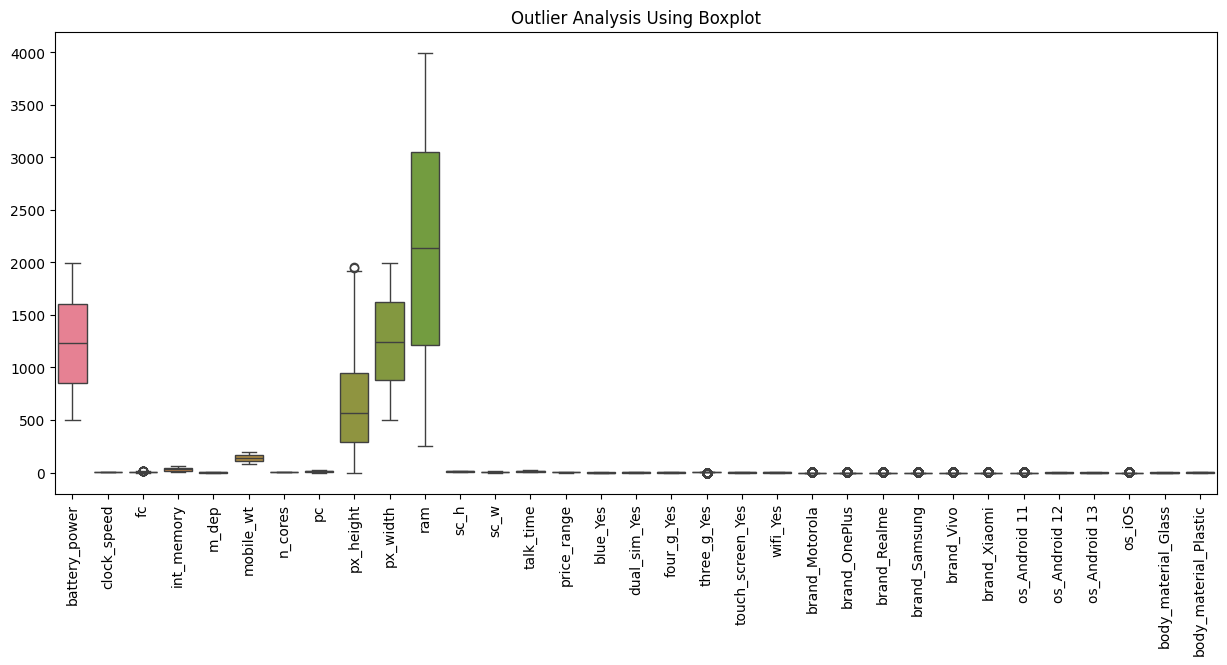


Final Refined Dataset:
   battery_power  clock_speed   fc  int_memory  m_dep  mobile_wt  n_cores  \
0          871.0          0.6  2.0        52.0    0.1      178.0      3.0   
1         1658.0          1.4  0.0        39.0    0.7      182.0      1.0   
2          987.0          2.3  9.0        17.0    0.8      124.0      7.0   
3         1703.0          0.5  5.0        23.0    0.2       92.0      6.0   
4          851.0          0.5  3.0        21.0    0.4      200.0      5.0   

     pc  px_height  px_width  ...  brand_Realme  brand_Samsung  brand_Vivo  \
0   3.0      194.0    1437.0  ...             0              0           1   
1   5.0      410.0     522.0  ...             0              0           0   
2  17.0      887.0    1274.0  ...             1              0           0   
3   7.0      134.0     521.0  ...             0              0           1   
4   7.0     1171.0    1263.0  ...             0              0           0   

   brand_Xiaomi  os_Android 11  os_Android 1

In [ ]:
# Experiment 2: Data Preprocessing, Missing Data and Outlier Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
df = pd.read_csv("/content/drive/My Drive/Colab Notebooks/train_modified_balanced.csv")

print("Original Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

# 2. Identify numerical and categorical columns
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include='object').columns

print("\nText/Categorical Columns:")
print(list(cat_cols))

# 3. Missing Value Analysis - BEFORE handling
print("\nMissing Values BEFORE Handling:")
print(df.isnull().sum())

# 4. Handle Missing Values
# Mean - first numerical column
if len(num_cols) > 0:
    df[num_cols[0]] = df[num_cols[0]].fillna(df[num_cols[0]].mean())

# Median - second numerical column
if len(num_cols) > 1:
    df[num_cols[1]] = df[num_cols[1]].fillna(df[num_cols[1]].median())

# Mode - categorical columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Handle any remaining numerical missing values using median
for col in num_cols[2:]:
    df[col] = df[col].fillna(df[col].median())

# 5. Missing Value Analysis - AFTER handling
print("\nMissing Values AFTER Handling:")
print(df.isnull().sum())

# 6. Convert Text to Numerical using One-Hot Encoding
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

print("\nDataset After One-Hot Encoding:")
print(df.head())

# 7. Remove Duplicate Records
print("\nDuplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)

# 8. Outlier Analysis using IQR
num_cols = df.select_dtypes(include=np.number).columns

print("\nOutlier Analysis:")

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, "->", outliers, "outliers")

# 9. Boxplot for Outlier Analysis
plt.figure(figsize=(15, 6))

sns.boxplot(data=df[num_cols])

plt.title("Outlier Analysis Using Boxplot")
plt.xticks(rotation=90)
plt.show()

# 10. Final Refined Dataset
print("\nFinal Refined Dataset:")
print(df.head())

print("\nFinal Dataset Shape:")
print(df.shape)

# 11. Save Refined Dataset
df.to_csv("refined_mobile_price.csv", index=False)

print("\nRefined dataset saved successfully!")